# Chapter 12: Approximate Relations

Companion notebook for **Chapter 12** of *Bernoulli Types: Two-Sided Error in Approximate Membership, Retrieval, and Computation*. Source files: `book/chapters/ch12/`. The chapter is a re-synchronized presentation of the relations manuscript, *Error contracts for approximate relations*, revised in October 2026 after an audit retracted several earlier claims.

A relation $R \subseteq T \times U$ is a set of pairs, and an approximate relation $\tilde R$ is a noisy membership predicate on $T \times U$ with the two rates of chapter 5. What the set-level chapters could leave implicit must now be explicit, because relational operators reuse their inputs: the exact relation (fixed, no prior), the construction randomness (sampled once, then frozen), and the **source identity** of each probe, the stored random outcome it reads (`def:source-model`). A tuple's rate is a property of one probe; a query's error depends on which stored outcomes its probes share.

This notebook follows the chapter:

1. **Sources** (§12.1 to §12.2). Repeated reads of one source are one outcome, not fresh trials; join outputs that share an operand tuple are correlated, with covariance $a(1 - a) b_1 b_2$ (`thm:join-correlation`).
2. **Operator rates** (§12.2). Projection rates are indexed by the fiber profile $(k, j)$ (`thm:projection-rates`); a join output has three pointwise false-positive regimes, so it is not a two-rate tuple (`thm:join-rates`). Operators compose through lineage over sources, not by chaining per-operator rate updates.
3. **Query error contracts** (§12.4). For a monotone lineage $F$ over independent one-sided sources, the worst-case query false-positive rate over all exact truth profiles is $1 - (1 - \fprate)^{s_0(F)}$ (`thm:query-contract`). The 12-cycle of binary witnesses has $s_0 = 8$, so a per-source rate of $0.05$ permits a query false-positive rate of $0.337$.
4. **A stored-filter calibration** (§12.4). On frozen partitioned Bloom filters, sizing each source at the tuple target $0.05$ passes an all-false check but gives a boundary-profile query FPR near $0.33$ (the chapter reports $0.329$); sizing by `eq:query-calibration` restores about $0.05$.
5. **The similarity join** (§12.5). MinHash supplies pointwise rates for the threshold relation, LSH banding prunes the candidates, and because both stages read the same signature they are dependent: the product rules do not apply, while the union bound does.

**Conventions:**
- $\fprate$ and $\fnrate$ are per-source false-positive and false-negative rates; $\tprate = 1 - \fnrate$.
- Exact probabilities of Boolean lineage are computed with `bernoulli.formula`, which evaluates a formula at a fixed latent assignment and handles repeated variables exactly.
- Similarity-join conventions: $\theta$ is the similarity threshold, $k$ the MinHash signature length, $b, r$ the LSH band and per-band row counts ($k = b r$). A *pair* is an ordered pair $(i, j)$ with $i \in R_1$, $j \in R_2$.
- All randomness is seeded for reproducibility. The invariants of §12.3 are not exercised here.

In [1]:
import hashlib
import itertools
import math
import random
import statistics
import struct
from collections import defaultdict
from functools import reduce

import numpy as np
import matplotlib.pyplot as plt

from bernoulli.formula import error_probability, output_probability, variables, worst_case_rates
from bernoulli.sets.composition import SetRates

rng = np.random.default_rng(seed=42)

print(f"NumPy      {np.__version__}")
print(f"Matplotlib {plt.matplotlib.__version__}")

NumPy      2.5.4
Matplotlib 3.11.2


## 1. Source Identity: Shared Outcomes Are Not Fresh Trials (§12.1 to §12.2)

Under the independent-source model each stored source bit $X_i$ is drawn once, and every probe that reads source $i$ sees the same $X_i$. Three consequences, each computed exactly with `bernoulli.formula` (a variable that occurs more than once is one observation feeding several places):

- **Repeated sources.** A conjunction that reads one absent source eight times at rate $0.05$ fires with probability $0.05$; treating the occurrences as independent gives $0.05^8 \approx 3.9 \times 10^{-11}$.
- **Canonical symmetric storage.** A structure that answers $R(a, b)$ and $R(b, a)$ from one canonical key gives the query $R(a, b) \land R(b, a)$ a single source as its lineage, so it errs at $\fprate$, not $\fprate^2$.
- **Join correlation** (`thm:join-correlation`). Two join outputs $(t, u, v_1)$ and $(t, u, v_2)$ share their $R_1$-pair. With every operand true-positive rate $0.9$ they are accepted together with probability $0.9^3 = 0.729$, while an independence assumption predicts $0.9^4 = 0.6561$; the covariance is $a(1 - a) b_1 b_2 = 0.0729$. The marginal of each output is still exact, and expected counts still add by linearity; what fails is any product over output tuples.

In [2]:
eps, tau = 0.05, 0.90
absent = SetRates(fpr=eps, fnr=0.0)

# Repeated source: AND of one absent source read eight times, versus eight independent sources.
x8 = variables(8)
repeated = reduce(lambda f, g: f & g, [x8[0]] * 8)
fresh = reduce(lambda f, g: f & g, list(x8))
p_repeated = output_probability(repeated, [absent] * 8, (False,) * 8)
p_fresh = output_probability(fresh, [absent] * 8, (False,) * 8)
print(f"one absent source read 8 times: {p_repeated:.4f};  8 independent absent sources: {p_fresh:.2e}")
assert math.isclose(p_repeated, eps) and math.isclose(p_fresh, eps ** 8)

# Canonical symmetric storage: R(a,b) and R(b,a) read one source; ordered storage reads two.
x1, x2 = variables(2)
p_canonical = output_probability(x1 & x1, [absent] * 2, (False, False))
p_ordered = output_probability(x1 & x2, [absent] * 2, (False, False))
print(f"R(a,b) and R(b,a), absent pair: canonical source {p_canonical:.4f}, ordered sources {p_ordered:.4f}")
assert math.isclose(p_canonical, eps) and math.isclose(p_ordered, eps ** 2)

# Join outputs sharing their R1-pair: x0 = R1(t,u), x1 = R2(u,v1), x2 = R2(u,v2), all true.
j0, j1, j2 = variables(3)
present = SetRates(fpr=0.0, fnr=1 - tau)
both = output_probability((j0 & j1) & (j0 & j2), [present] * 3, (True, True, True))
marg = output_probability(j0 & j1, [present] * 3, (True, True, True))
cov = both - marg ** 2
a, b1, b2 = tau, tau, tau
print(f"two true join outputs sharing an R1-pair: P(both accepted) = {both:.4f}, "
      f"product of marginals = {marg ** 2:.4f}, covariance = {cov:.4f} = a(1-a)b1b2 = {a * (1 - a) * b1 * b2:.4f}")
print(f"  joint / product = {both / marg ** 2:.3f}")
assert math.isclose(both, 0.729) and math.isclose(marg ** 2, 0.6561)
assert math.isclose(cov, a * (1 - a) * b1 * b2)

one absent source read 8 times: 0.0500;  8 independent absent sources: 3.91e-11
R(a,b) and R(b,a), absent pair: canonical source 0.0500, ordered sources 0.0025
two true join outputs sharing an R1-pair: P(both accepted) = 0.7290, product of marginals = 0.6561, covariance = 0.0729 = a(1-a)b1b2 = 0.0729
  joint / product = 1.111


## 2. Operator Rates (§12.2)

**Projection** (`thm:projection-rates`) is an OR over the fiber of a projected tuple. With fan-in $k(s)$ and $j(s)$ true members in the fiber, under the independent-tuple model the projection accepts $s$ with probability $1 - (1 - \tprate)^{j}(1 - \fprate)^{k - j}$. A negative projected tuple ($j = 0$) has false-positive rate $1 - (1 - \fprate)^k \ge \fprate$, amplified by the fan-in, and the true-positive side is boosted. Uniform fan-in alone does not give a common true-positive rate: at $(\fprate, \tprate) = (0.05, 0.90)$, fibers with $(k, j) = (3, 1)$ and $(3, 2)$ have true-positive rates $0.90975$ and $0.9905$. The attained profiles $(k, j)$ are the rate blocks.

**Natural join** (`thm:join-rates`) is the AND of two noisy tests. A true triple has false-negative rate $1 - \tprate_1 \tprate_2$; a triple outside the join is accepted with probability $\fprate_1 \tprate_2$ if only its $R_1$-pair is absent, $\tprate_1 \fprate_2$ if only its $R_2$-pair is absent, and $\fprate_1 \fprate_2$ if both are. Without a distribution on queries the three regimes stay distinct: a join output is not a two-rate tuple, and the bare product is only the both-absent corner. The chapter's worked example joins a friend-of relation ($\fprate_F = 0.05$) with a coworker relation ($\fprate_C = 0.02$), both FNR-zero: $0.001$ in the both-absent corner, $0.02$ for a half-matched triple.

Chaining a two-rate update per operator up an expression tree fails for exactly this reason (chapter 3's `ex:two-rate-counterexample`); the marginal of a whole query is a polynomial in the source rates read off its lineage.

In [3]:
two_sided = SetRates(fpr=eps, fnr=1 - tau)

# Projection: OR over a fiber of k candidate tuples, j of them true members.
def projection_accept(k, j):
    xs = variables(k)
    fiber_or = reduce(lambda f, g: f | g, list(xs))
    word = tuple(i < j for i in range(k))
    return output_probability(fiber_or, [two_sided] * k, word)


print("projection acceptance by fiber profile (k, j), (eps, tau) = (0.05, 0.90):")
for k_f, j_f in ((1, 0), (3, 0), (3, 1), (3, 2), (3, 3), (10, 0)):
    p = projection_accept(k_f, j_f)
    closed = 1 - (1 - tau) ** j_f * (1 - eps) ** (k_f - j_f)
    kind = "FPR" if j_f == 0 else "TPR"
    print(f"  (k, j) = ({k_f:>2}, {j_f}): {kind} = {p:.5f}   closed form {closed:.5f}")
    assert math.isclose(p, closed)
assert round(projection_accept(3, 1), 5) == 0.90975 and round(projection_accept(3, 2), 4) == 0.9905

# Natural join of a friend-of relation (fpr 0.05) and a coworker relation (fpr 0.02), both FNR-zero.
F_rates, C_rates = SetRates(fpr=0.05, fnr=0.0), SetRates(fpr=0.02, fnr=0.0)
f_pair, c_pair = variables(2)
join = f_pair & c_pair
print("\njoin regimes, friend-of (0.05) and coworker (0.02):")
regimes = {
    "both pairs absent      ": (False, False),
    "only friend pair absent": (False, True),
    "only coworker absent   ": (True, False),
}
for label, word in regimes.items():
    print(f"  {label}: accepted with probability {output_probability(join, [F_rates, C_rates], word):.4f}")
assert math.isclose(output_probability(join, [F_rates, C_rates], (False, False)), 0.001)
assert math.isclose(output_probability(join, [F_rates, C_rates], (True, False)), 0.02)
worst = worst_case_rates(join, [F_rates, C_rates])
print(f"  worst case over negative words: {worst.fpr:.4f} = max(fpr_F, fpr_C), not the product")
assert math.isclose(worst.fpr, 0.05)

projection acceptance by fiber profile (k, j), (eps, tau) = (0.05, 0.90):
  (k, j) = ( 1, 0): FPR = 0.05000   closed form 0.05000
  (k, j) = ( 3, 0): FPR = 0.14263   closed form 0.14263
  (k, j) = ( 3, 1): TPR = 0.90975   closed form 0.90975
  (k, j) = ( 3, 2): TPR = 0.99050   closed form 0.99050
  (k, j) = ( 3, 3): TPR = 0.99900   closed form 0.99900
  (k, j) = (10, 0): FPR = 0.40126   closed form 0.40126

join regimes, friend-of (0.05) and coworker (0.02):
  both pairs absent      : accepted with probability 0.0010
  only friend pair absent: accepted with probability 0.0500
  only coworker absent   : accepted with probability 0.0200
  worst case over negative words: 0.0500 = max(fpr_F, fpr_C), not the product


## 3. Query Error Contracts (§12.4)

Since no prior over exact databases is assumed, the natural guarantee for a query is a **contract**: a bound valid for every exact truth profile with the given answer. For a nonconstant monotone lineage $F$ on distinct sources, in the one-sided false-positive model (each source reports $x_i \lor E_i$, $E_i \sim \mathrm{Bernoulli}(\fprate_i)$) and the separate one-sided false-negative model,
$$\mathcal{E}_0(F) = \max_{x : F(x) = 0} \Pr[F(Y^+(x)) = 1], \qquad \mathcal{E}_1(F) = \max_{x : F(x) = 1} \Pr[F(Y^-(x)) = 0].$$
`thm:query-contract`: for homogeneous rates $\mathcal{E}_0(F) = 1 - (1 - \fprate)^{s_0(F)}$ and $\mathcal{E}_1(F) = 1 - (1 - \fnrate)^{s_1(F)}$, where $s_0$ and $s_1$ are the one-sided sensitivities (the largest number of zeros of a maximal false input, and the largest witness width). For witnesses of width and source occurrence at most two, `thm:query-contract-cycles` gives $s_0 = \sum_c (n_c - \lceil n_c / 3 \rceil)$ over the path and cycle components.

The 12-cycle of binary witnesses, $F = \bigvee_{j} (X_j \land X_{j+1 \bmod 12})$, has $s_0 = 8$ and $s_1 = 2$. A per-source rate of $0.05$ therefore permits a worst-case query false-positive rate of $1 - 0.95^8 \approx 0.337$, attained at the false profile with true sources at $\{0, 3, 6, 9\}$; the all-false profile, which needs two adjacent false positives, errs far less often. Validating a structure on the all-false profile alone does not validate the contract. Three further facts:

- In a two-sided channel the same expressions are upper bounds, not equalities: for $X_1 \land X_2$ with $\fprate \le 1 - \fnrate$ the worst two-sided false-positive rate is $\fprate(1 - \fnrate)$, while the one-sided formula gives $\fprate$.
- Without independence, with only marginal bounds, the sharp envelope is $\min\{1, \fprate\, s_0\}$ (`thm:query-contract-dependent`), $0.40$ here.
- For a query target $\delta$, sources sized as $\fprate \le 1 - (1 - \delta)^{1/s_0}$ suffice under independence (`eq:query-calibration`), and $\fprate \le \delta / s_0$ under arbitrary dependence.

We verify the contract theorem against `bernoulli.formula.worst_case_rates` (the exact maximum over all latent words) on cycles of $3$ to $10$ sources, then check the 12-cycle by brute force over all $4096$ truth profiles.

In [4]:
def cycle_formula(n_c):
    xs = variables(n_c)
    return reduce(lambda f, g: f | g, [xs[j] & xs[(j + 1) % n_c] for j in range(n_c)])


def s0_cycle(n_c):
    return n_c - math.ceil(n_c / 3)              # thm:query-contract-cycles, one cycle component


fp_only, fn_only = SetRates(fpr=0.05, fnr=0.0), SetRates(fpr=0.0, fnr=0.10)
print(" n_c  s0  E0 (worst_case_rates)  1-(1-eps)^s0   E1 (worst_case_rates)  1-(1-omega)^2")
for n_c in range(3, 11):
    F = cycle_formula(n_c)
    e0 = worst_case_rates(F, [fp_only] * n_c).fpr
    e1 = worst_case_rates(F, [fn_only] * n_c).fnr
    print(f"{n_c:>4}  {s0_cycle(n_c):>2}  {e0:>21.6f}  {1 - 0.95 ** s0_cycle(n_c):>12.6f}   "
          f"{e1:>21.6f}  {1 - 0.9 ** 2:>13.6f}")
    assert math.isclose(e0, 1 - 0.95 ** s0_cycle(n_c)) and math.isclose(e1, 1 - 0.9 ** 2)


# The 12-cycle. Exact query-FP probability for one truth profile, by a transfer-matrix pass.
def cycle_value(bits):
    return any(bits[i] and bits[(i + 1) % len(bits)] for i in range(len(bits)))


def cycle_probability(truth, p):
    rates = [1.0 if t else p for t in truth]
    total = 0.0
    for first in (0, 1):
        state = {(first, False): rates[0] if first else 1 - rates[0]}
        for rate in rates[1:]:
            nxt = defaultdict(float)
            for (last, witnessed), pr in state.items():
                for bit, pb in ((1, rate), (0, 1 - rate)):
                    nxt[(bit, witnessed or (last and bit))] += pr * pb
            state = nxt
        total += sum(pr for (last, witnessed), pr in state.items() if witnessed or (last and first))
    return total


N_C = 12
false_profiles = [t for t in itertools.product((False, True), repeat=N_C) if not cycle_value(t)]
maximal = [t for t in false_profiles
           if all(cycle_value(t[:i] + (True,) + t[i + 1:]) for i in range(N_C) if not t[i])]
s0_brute = max(N_C - sum(t) for t in maximal)
e0_brute, argmax = max((cycle_probability(t, 0.05), t) for t in false_profiles)
boundary = tuple(i in (0, 3, 6, 9) for i in range(N_C))
F12 = cycle_formula(N_C)
e_boundary = error_probability(F12, [fp_only] * N_C, boundary)
e_allfalse = error_probability(F12, [fp_only] * N_C, (False,) * N_C)

print(f"\n12-cycle: {len(false_profiles)} false profiles, {len(maximal)} maximal; s0 = {s0_brute} "
      f"(theorem {s0_cycle(N_C)})")
print(f"  brute-force worst query FPR = {e0_brute:.4f} at true sources "
      f"{[i for i, t in enumerate(argmax) if t]}; 1 - 0.95^8 = {1 - 0.95 ** 8:.4f}")
print(f"  bernoulli.formula: boundary profile {{0,3,6,9}} {e_boundary:.4f}, all-false profile {e_allfalse:.4f}")
assert s0_brute == s0_cycle(N_C) == 8
assert math.isclose(e0_brute, 1 - 0.95 ** 8) and math.isclose(e_boundary, e0_brute)
assert e_allfalse < 0.05 < e_boundary

# Two-sided channels: the one-sided expressions are upper bounds, not equalities.
y1, y2 = variables(2)
two = worst_case_rates(y1 & y2, [SetRates(fpr=0.05, fnr=0.10)] * 2).fpr
print(f"\nX1 AND X2, two-sided (0.05, 0.10): worst FPR {two:.4f} = eps(1 - omega), one-sided formula gives 0.05")
assert math.isclose(two, 0.05 * 0.9)

# Marginal-only envelope and calibration (eq:query-calibration).
delta, s0 = 0.05, s0_brute
eps_indep = 1 - (1 - delta) ** (1 / s0)
eps_union = delta / s0
print(f"marginal-only envelope at eps = 0.05: min(1, eps s0) = {min(1.0, 0.05 * s0):.2f}")
print(f"calibrated source rate for delta = {delta}: independent {eps_indep:.6f}, any dependence {eps_union:.6f}")
assert math.isclose(max(cycle_probability(t, eps_indep) for t in false_profiles), delta)

 n_c  s0  E0 (worst_case_rates)  1-(1-eps)^s0   E1 (worst_case_rates)  1-(1-omega)^2
   3   2               0.097500      0.097500                0.190000       0.190000
   4   2               0.097500      0.097500                0.190000       0.190000
   5   3               0.142625      0.142625                0.190000       0.190000
   6   4               0.185494      0.185494                0.190000       0.190000
   7   4               0.185494      0.185494                0.190000       0.190000


   8   5               0.226219      0.226219                0.190000       0.190000


   9   6               0.264908      0.264908                0.190000       0.190000


  10   6               0.264908      0.264908                0.190000       0.190000

12-cycle: 322 false profiles, 29 maximal; s0 = 8 (theorem 8)
  brute-force worst query FPR = 0.3366 at true sources [0, 3, 6, 9]; 1 - 0.95^8 = 0.3366
  bernoulli.formula: boundary profile {0,3,6,9} 0.3366, all-false profile 0.0283

X1 AND X2, two-sided (0.05, 0.10): worst FPR 0.0450 = eps(1 - omega), one-sided formula gives 0.05
marginal-only envelope at eps = 0.05: min(1, eps s0) = 0.40
calibrated source rate for delta = 0.05: independent 0.006391, any dependence 0.006250


## 4. A Stored-Filter Calibration (§12.4)

The relations manuscript tests the contract on a concrete structure (Sec. 7): a frozen partitioned Bloom filter representing a symmetric relation, $k$ partitions of $m$ bits with one hash per partition, queried from the bit array alone. Canonical mode stores one key per unordered pair. Under ideal independent hashing and conditional on the inserted keys' hashes, an absent key tests positive with probability $p(C) = \prod_j o_j / m$, where $o_j$ is the occupied count of partition $j$, which is exactly the shared-rate setting of `cor:query-contract-shared`. The build retries salts until $p(C) \le \fprate$, an acceptance test that inspects only inserted-key hashes.

The workload is the 12-cycle query, $128$ fixed bundles for each of three profiles (all sources absent; the extremal false profile $\{0, 3, 6, 9\}$; a true profile with an adjacent pair) over an exact relation of $2{,}816$ member orbits, with query target $\delta = 0.05$. The chapter builds each sizing $160$ times (`tab:filter-calibration`):

| Sizing | Bytes | All-false | Boundary | 95% interval |
|--------|------:|----------:|---------:|:------------:|
| Canonical, per tuple | 2,250 | 0.02646 | 0.32915 | [0.32264, 0.33566] |
| Canonical, per query | 3,752 | 0.00049 | 0.04907 | [0.04594, 0.05220] |
| Ordered OR, per query | 8,482 | 0.00039 | 0.05103 | [0.04815, 0.05390] |

Below is a reduced replication of the two canonical rows, $64$ builds per sizing, with BLAKE2b as the concrete hash (the manuscript's script, `papers/bernoulli_relations/code/filter_calibration.py`, runs the full experiment). As there, the construction-level means are the sampling units, so no independence of same-build queries is assumed, and the ideal-model prediction for each build is computed from its recorded occupancies.

In [5]:
HEADER_BYTES = 40     # the serialized format's header: magic, dimensions, count, 16-byte salt


def bloom_dimensions(count, target):
    partitions = max(1, math.ceil(-math.log2(target)))
    occupancy = target ** (1.0 / partitions)
    inverse_bits = -math.expm1(math.log1p(-occupancy) / count)
    return partitions, 8 * math.ceil((1.0 / inverse_bits) / 8)


class FrozenPartitionedBloom:
    def __init__(self, keys, target, salt):
        self.k, self.m = bloom_dimensions(len(keys), target)
        self.salt = salt
        self.parts = [bytearray(self.m // 8) for _ in range(self.k)]
        for key in keys:
            for j in range(self.k):
                pos = self._position(key, j)
                self.parts[j][pos >> 3] |= 1 << (pos & 7)
        self.occupancy = [sum(byte.bit_count() for byte in part) for part in self.parts]
        self.p_cond = math.prod(o / self.m for o in self.occupancy)    # ideal conditional key FPR
        self.payload_bytes = HEADER_BYTES + self.k * self.m // 8

    def _position(self, key, j):
        digest = hashlib.blake2b(struct.pack(">I", j) + key, key=self.salt, digest_size=16).digest()
        return int.from_bytes(digest, "big") % self.m

    def contains(self, key):
        for j in range(self.k):
            pos = self._position(key, j)
            if not self.parts[j][pos >> 3] & (1 << (pos & 7)):
                return False
        return True


def canonical_key(u, v):
    return struct.pack(">QQ", min(u, v), max(u, v))     # one key per unordered pair


# Workload: 2048 background orbits plus three profiles of 128 disjoint 12-cycle bundles.
BUNDLES, BACKGROUND = 128, 2048
profiles = {
    "all-false": (False,) * N_C,
    "boundary": boundary,
    "true edge": (True, True) + (False,) * (N_C - 2),
}
true_keys = {canonical_key(2 * i, 2 * i + 1) for i in range(BACKGROUND)}
groups, next_source = {}, BACKGROUND
for name, truth in profiles.items():
    bundles = []
    for _ in range(BUNDLES):
        pairs = [(2 * i, 2 * i + 1) for i in range(next_source, next_source + N_C)]
        true_keys.update(canonical_key(u, v) for (u, v), bit in zip(pairs, truth) if bit)
        bundles.append(pairs)
        next_source += N_C
    groups[name] = (truth, bundles)
true_keys = sorted(true_keys)
print(f"exact relation: {len(true_keys)} member orbits")
assert len(true_keys) == 2816

methods = {"per tuple": delta, "per query": eps_indep}
BUILDS = 64
salt_rng = random.Random(20261021)
measured = {m: {g: [] for g in groups} for m in methods}
ideal = {m: {g: [] for g in groups} for m in methods}
payload = {}
for build in range(BUILDS):
    for method, target in methods.items():
        while True:                                   # retry salts on inserted-key occupancy only
            salt = salt_rng.getrandbits(128).to_bytes(16, "big")
            filt = FrozenPartitionedBloom(true_keys, target, salt)
            if filt.p_cond <= target:
                break
        payload[method] = filt.payload_bytes
        assert all(filt.contains(key) for key in true_keys), "FNR-zero by construction"
        for name, (truth, bundles) in groups.items():
            answers = [cycle_value([filt.contains(canonical_key(u, v)) for u, v in pairs]) for pairs in bundles]
            measured[method][name].append(sum(answers) / len(answers))
            ideal[method][name].append(cycle_probability(truth, filt.p_cond))

print(f"\n{'sizing':<20} {'bytes':>6} {'all-false':>10} {'boundary':>10} {'95% interval':>20} {'ideal model':>12}")
summary = {}
for method in methods:
    vals = measured[method]["boundary"]
    mean = statistics.mean(vals)
    se = statistics.stdev(vals) / math.sqrt(BUILDS)
    summary[method] = (mean, se, statistics.mean(ideal[method]["boundary"]))
    print(f"canonical, {method:<9} {payload[method]:>6} {statistics.mean(measured[method]['all-false']):>10.5f} "
          f"{mean:>10.5f}   [{mean - 1.96 * se:.5f}, {mean + 1.96 * se:.5f}] {summary[method][2]:>12.5f}")
    assert statistics.mean(measured[method]["true edge"]) == 1.0, "true queries are never missed"
    assert abs(mean - summary[method][2]) < 4 * se, "measured boundary FPR must match the ideal model"

naive, calibrated = summary["per tuple"], summary["per query"]
assert payload["per tuple"] == 2250 and payload["per query"] == 3752, "same dimensions as the chapter"
assert statistics.mean(measured["per tuple"]["all-false"]) < delta < 0.25 < naive[0]
assert abs(calibrated[0] - delta) < 4 * calibrated[1]
print(f"\nper-tuple sizing passes an all-false check against {delta} but misses the query target by "
      f"a factor of {naive[0] / delta:.1f}; calibrated sizing restores about {delta}")

k_u, m_u = bloom_dimensions(len(true_keys), eps_union)
union_bytes = HEADER_BYTES + k_u * m_u // 8
print(f"union-bound sizing (delta/s0 = {eps_union:.5f}) would take {union_bytes} bytes against "
      f"{payload['per query']}: {union_bytes - payload["per query"]} bytes ({100 * (union_bytes / payload["per query"] - 1):.2f}%) more")
assert union_bytes == 3768

exact relation: 2816 member orbits



sizing                bytes  all-false   boundary         95% interval  ideal model
canonical, per tuple   2250    0.02795    0.33435   [0.32425, 0.34445]      0.33238
canonical, per query   3752    0.00073    0.04749   [0.04205, 0.05292]      0.04884

per-tuple sizing passes an all-false check against 0.05 but misses the query target by a factor of 6.7; calibrated sizing restores about 0.05
union-bound sizing (delta/s0 = 0.00625) would take 3768 bytes against 3752: 16 bytes (0.43%) more


## 5. The Similarity Join (§12.5)

For relations whose rows are token sets, the similarity join at threshold $\theta$ is $R_1 \bowtie_\theta R_2 = \{(r_1, r_2) : J(r_1, r_2) \ge \theta\}$. The sketch evaluation is the approximate relation $\tilde S_\theta(r_1, r_2) = [\hat J(r_1, r_2) \ge \theta]$, with $\hat J$ the MinHash estimate of chapter 10, and locality-sensitive hashing prunes the candidate pairs. The sections below build the setting on synthetic data:

1. **Synthetic relations** with a planted overlap structure: two relations of 1000 rows each, with 100 row pairs engineered to have $J \ge 0.5$ and the rest near-disjoint.
2. **MinHash signatures** of length $k = 200$ per row, with the per-index SHA-256 hash family of the chapter 10 notebook.
3. **Sampled exact Jaccard** over 10000 random row pairs as ground truth.
4. **The threshold test** $\hat J \ge \theta$ on the sample, with its FPR and FNR.
5. **LSH bucketing** with $b = 20$ bands of $r = 10$ rows over the full $1000 \times 1000$ relation, and the precision and recall of the candidate set.
6. **The dependence between the stages**: the candidate test and the threshold test read the same signature.
7. **The chapter's worked example** of the banding trade-off.

### 5.1 Synthetic relations with planted overlap

Two relations $R_1, R_2$, each with $|R_1| = |R_2| = 1000$ rows. Each row is a set of 10 tokens drawn from a shared vocabulary of 200 tokens.

**Overlap design.** Pick 100 row indices in $R_1$ and 100 in $R_2$ (without replacement on each side). For pair index $p \in \{0, \ldots, 99\}$, planting forces row $R_1[i_p]$ and row $R_2[j_p]$ to share at least 7 tokens out of 10 each, giving $|A \cap B| \ge 7$, $|A \cup B| \le 13$, hence $J \ge 7/13 \approx 0.538 \ge 0.5$.

The other $1000 \cdot 1000 - 100 = 999900$ cross-relation pairs are generated by uniform random sampling of 10 tokens from 200 per row. The expected Jaccard of two such random rows is small: with two size-10 subsets of a size-200 vocabulary, expected $|A \cap B| \approx 10 \cdot 10 / 200 = 0.5$, so expected $J \approx 0.5 / (20 - 0.5) \approx 0.026$. Almost all background pairs land well below $\theta = 0.5$.

The result is a clean binary classification setting: 100 *similar* pairs (planted), $\approx 999900$ *dissimilar* pairs.

In [6]:
VOCAB_SIZE = 200
ROW_SIZE = 10
N_ROWS = 1000
N_PLANTED = 100
SHARED_MIN = 7  # planted pairs share at least this many tokens

vocab = np.array([f"tok-{i:03d}" for i in range(VOCAB_SIZE)])


def random_row(rng_local):
    idx = rng_local.choice(VOCAB_SIZE, size=ROW_SIZE, replace=False)
    return frozenset(vocab[idx].tolist())


def planted_pair(rng_local):
    # Shared core of SHARED_MIN tokens; each side fills the remaining slots independently.
    core_idx = rng_local.choice(VOCAB_SIZE, size=SHARED_MIN, replace=False)
    core = set(vocab[core_idx].tolist())
    remaining_pool = [v for v in vocab.tolist() if v not in core]
    extra_a_idx = rng_local.choice(len(remaining_pool), size=ROW_SIZE - SHARED_MIN, replace=False)
    extra_b_idx = rng_local.choice(len(remaining_pool), size=ROW_SIZE - SHARED_MIN, replace=False)
    extras_a = {remaining_pool[i] for i in extra_a_idx}
    extras_b = {remaining_pool[i] for i in extra_b_idx}
    return frozenset(core | extras_a), frozenset(core | extras_b)


rng_data = np.random.default_rng(seed=2026)

R1 = [random_row(rng_data) for _ in range(N_ROWS)]
R2 = [random_row(rng_data) for _ in range(N_ROWS)]

# Pick planted indices on each side without replacement.
planted_i = rng_data.choice(N_ROWS, size=N_PLANTED, replace=False)
planted_j = rng_data.choice(N_ROWS, size=N_PLANTED, replace=False)

# Overwrite the planted positions with engineered high-overlap pairs.
planted_pairs = set()
for p in range(N_PLANTED):
    a, b = planted_pair(rng_data)
    R1[int(planted_i[p])] = a
    R2[int(planted_j[p])] = b
    planted_pairs.add((int(planted_i[p]), int(planted_j[p])))

# Quick descriptive stats on a planted pair vs a random pair.
def jaccard(a, b):
    if not a and not b:
        return 1.0
    return len(a & b) / len(a | b)


sample_planted = next(iter(planted_pairs))
sample_random = (0, 0) if (0, 0) not in planted_pairs else (1, 1)
i_p, j_p = sample_planted
i_r, j_r = sample_random

print(f"|R1| = {len(R1)}, |R2| = {len(R2)}")
print(f"vocab size = {VOCAB_SIZE}, row size = {ROW_SIZE}")
print(f"Planted pairs: {len(planted_pairs)} (each with at least {SHARED_MIN} shared tokens)")
print()
print(f"Sample planted pair (R1[{i_p}], R2[{j_p}]):")
print(f"  |A| = {len(R1[i_p])}, |B| = {len(R2[j_p])}, |A int B| = {len(R1[i_p] & R2[j_p])}, J = {jaccard(R1[i_p], R2[j_p]):.4f}")
print(f"Sample random pair (R1[{i_r}], R2[{j_r}]):")
print(f"  |A| = {len(R1[i_r])}, |B| = {len(R2[j_r])}, |A int B| = {len(R1[i_r] & R2[j_r])}, J = {jaccard(R1[i_r], R2[j_r]):.4f}")

|R1| = 1000, |R2| = 1000
vocab size = 200, row size = 10
Planted pairs: 100 (each with at least 7 shared tokens)

Sample planted pair (R1[315], R2[972]):
  |A| = 10, |B| = 10, |A int B| = 7, J = 0.5385
Sample random pair (R1[0], R2[0]):
  |A| = 10, |B| = 10, |A int B| = 0, J = 0.0000


### 5.2 MinHash signatures

For each row in each relation, compute a MinHash signature of length $k = 200$ using the per-slot SHA-256 hash family from the chapter 10 notebook (\S3). The signature of a set $A$ is $\sigma(A) = (\min_{a \in A} h_1(a), \ldots, \min_{a \in A} h_k(a))$.

Storage: 2000 signatures of length 200 each, every slot a 64-bit integer. Total $2000 \cdot 200 \cdot 8 = 3.2 \cdot 10^6$ bytes ($\approx 3$ MB), independent of vocabulary or row size.

In [7]:
K_MINHASH = 200
UINT64_MAX = (1 << 64) - 1


class MinHash:
    """MinHash with k independent SHA256-based hash functions (per-slot salt)."""

    def __init__(self, k, seed=0):
        self.k = int(k)
        self.seed = int(seed)
        self._salts = [
            hashlib.sha256(f"mh-{self.seed}-{i}".encode()).digest()
            for i in range(self.k)
        ]

    def _h64(self, i, item):
        digest = hashlib.sha256(self._salts[i] + str(item).encode()).digest()
        return int.from_bytes(digest[:8], "big")

    def signature(self, items):
        sig = np.full(self.k, UINT64_MAX, dtype=np.uint64)
        for x in items:
            for i in range(self.k):
                v = self._h64(i, x)
                if v < sig[i]:
                    sig[i] = v
        return sig


mh = MinHash(k=K_MINHASH, seed=0)

sigs_R1 = np.empty((N_ROWS, K_MINHASH), dtype=np.uint64)
sigs_R2 = np.empty((N_ROWS, K_MINHASH), dtype=np.uint64)

for i, row in enumerate(R1):
    sigs_R1[i] = mh.signature(row)
for j, row in enumerate(R2):
    sigs_R2[j] = mh.signature(row)

print(f"sigs_R1.shape = {sigs_R1.shape}")
print(f"sigs_R2.shape = {sigs_R2.shape}")
print(f"Total signature storage: {(sigs_R1.nbytes + sigs_R2.nbytes) / 1e6:.2f} MB")
print()
# Spot check: a planted pair should have many matching slots; a random pair very few.
ip, jp = sample_planted
ir, jr = sample_random
match_planted = int(np.sum(sigs_R1[ip] == sigs_R2[jp]))
match_random = int(np.sum(sigs_R1[ir] == sigs_R2[jr]))
print(f"Planted pair (R1[{ip}], R2[{jp}]): {match_planted}/{K_MINHASH} matching slots, J_hat = {match_planted/K_MINHASH:.4f}")
print(f"Random  pair (R1[{ir}], R2[{jr}]): {match_random}/{K_MINHASH} matching slots, J_hat = {match_random/K_MINHASH:.4f}")

sigs_R1.shape = (1000, 200)
sigs_R2.shape = (1000, 200)
Total signature storage: 3.20 MB

Planted pair (R1[315], R2[972]): 106/200 matching slots, J_hat = 0.5300
Random  pair (R1[0], R2[0]): 0/200 matching slots, J_hat = 0.0000


### 5.3 Sampled exact Jaccard as ground truth

Computing exact $J$ for all $10^6$ cross-relation pairs is exactly the cost we are trying to avoid; doing it once on a smaller sample is fine for validation. Sample 10000 pairs $(i, j)$ uniformly at random (with replacement on the index pair, distinct in practice with extremely high probability), augmented with the 100 planted pairs so the *similar* class is well represented.

For each sampled pair compute (a) the exact Jaccard $J(R_1[i], R_2[j])$ and (b) the MinHash estimate $\hat J$ from the signatures. The next cell uses the resulting joint sample to measure MinHash accuracy.

In [8]:
N_SAMPLE = 10_000
rng_sample = np.random.default_rng(seed=7)

sampled_i = rng_sample.integers(0, N_ROWS, size=N_SAMPLE)
sampled_j = rng_sample.integers(0, N_ROWS, size=N_SAMPLE)

# Augment with all planted pairs so the similar class is properly represented.
planted_list = sorted(planted_pairs)
extra_i = np.array([p[0] for p in planted_list], dtype=np.int64)
extra_j = np.array([p[1] for p in planted_list], dtype=np.int64)
all_i = np.concatenate([sampled_i, extra_i])
all_j = np.concatenate([sampled_j, extra_j])
n_pairs = len(all_i)

J_true = np.empty(n_pairs, dtype=np.float64)
J_hat = np.empty(n_pairs, dtype=np.float64)
for idx in range(n_pairs):
    i, j = int(all_i[idx]), int(all_j[idx])
    J_true[idx] = jaccard(R1[i], R2[j])
    J_hat[idx] = float(np.mean(sigs_R1[i] == sigs_R2[j]))

# Mark which sampled rows are planted similar pairs.
is_planted = np.array([(int(all_i[idx]), int(all_j[idx])) in planted_pairs for idx in range(n_pairs)])

n_similar = int(np.sum(J_true >= 0.5))
print(f"Sampled pairs: {n_pairs} (including {len(planted_list)} planted)")
print(f"True J >= 0.5 in sample: {n_similar}")
print(f"True J <  0.5 in sample: {n_pairs - n_similar}")
print()
print(f"Background J stats (uniform-sample rows only):")
bg_mask = ~is_planted
print(f"  mean = {J_true[bg_mask].mean():.4f}, max = {J_true[bg_mask].max():.4f}, fraction >= 0.5 = {(J_true[bg_mask] >= 0.5).mean():.4f}")

Sampled pairs: 10100 (including 100 planted)
True J >= 0.5 in sample: 100
True J <  0.5 in sample: 10000

Background J stats (uniform-sample rows only):
  mean = 0.0273, max = 0.2500, fraction >= 0.5 = 0.0000


### 5.4 MinHash estimator accuracy on the sample

Per chapter 10 \S10.4, $\hat J$ is the mean of $k$ Bernoulli$(J)$ trials, so the absolute error has standard deviation $\sqrt{J(1-J)/k}$. At $k = 200$ the worst-case SE (over $J \in [0,1]$) is $\sqrt{0.25 / 200} = 0.0354$, attained at $J = 0.5$.

Sanity target: the *mean* absolute error $|\hat J - J|$ across the sample should be well within $0.05$, and the fraction of pairs with $|\hat J - J| \le 0.05$ should be high.

MinHash accuracy on 10100 sampled pairs (k = 200):
  mean |J_hat - J| = 0.0058
  max  |J_hat - J| = 0.0915
  fraction within +/- 0.05 = 0.9972
  fraction within +/- 0.10 = 1.0000

Theoretical worst-case SE (at J = 0.5): sqrt(0.25/k) = 0.0354


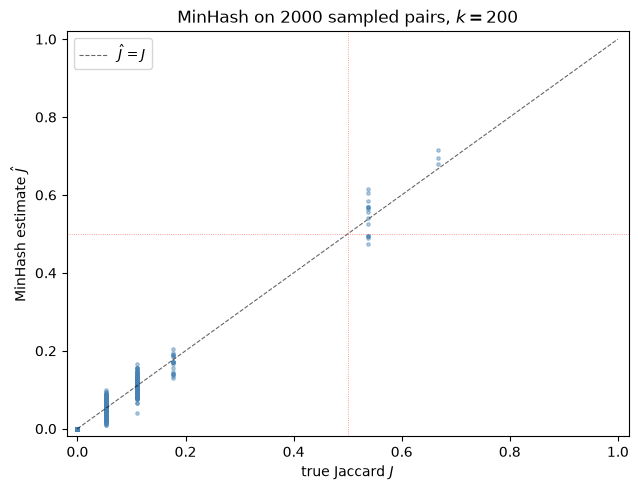

In [9]:
abs_err = np.abs(J_hat - J_true)

print(f"MinHash accuracy on {n_pairs} sampled pairs (k = {K_MINHASH}):")
print(f"  mean |J_hat - J| = {abs_err.mean():.4f}")
print(f"  max  |J_hat - J| = {abs_err.max():.4f}")
print(f"  fraction within +/- 0.05 = {(abs_err <= 0.05).mean():.4f}")
print(f"  fraction within +/- 0.10 = {(abs_err <= 0.10).mean():.4f}")
print()
worst_case_se = math.sqrt(0.25 / K_MINHASH)
print(f"Theoretical worst-case SE (at J = 0.5): sqrt(0.25/k) = {worst_case_se:.4f}")

# Scatter of J_hat against J_true (sample for readability).
plot_idx = rng_sample.choice(n_pairs, size=min(2000, n_pairs), replace=False)
fig, ax = plt.subplots(figsize=(6.5, 5.0))
ax.scatter(J_true[plot_idx], J_hat[plot_idx], s=6, alpha=0.4, color="steelblue")
ax.plot([0, 1], [0, 1], "k--", lw=0.8, alpha=0.6, label="$\\hat J = J$")
ax.axhline(0.5, color="red", lw=0.6, alpha=0.5, linestyle=":")
ax.axvline(0.5, color="red", lw=0.6, alpha=0.5, linestyle=":")
ax.set_xlabel("true Jaccard $J$")
ax.set_ylabel("MinHash estimate $\\hat J$")
ax.set_title(f"MinHash on 2000 sampled pairs, $k = {K_MINHASH}$")
ax.set_xlim(-0.02, 1.02)
ax.set_ylim(-0.02, 1.02)
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

### 5.5 The threshold test: FPR and FNR

Threshold the MinHash estimator at $\theta = 0.5$: a sampled pair is *flagged* if $\hat J \ge 0.5$. Compare against the binary truth label $J \ge 0.5$.

- **False positive rate** $\fprate = \Pr[\hat J \ge \theta \mid J < \theta]$: of the dissimilar pairs in the sample, what fraction are wrongly flagged?
- **False negative rate** $\fnrate = \Pr[\hat J < \theta \mid J \ge \theta]$: of the similar pairs in the sample, what fraction are missed?

For a fixed pair these are pointwise rates of $\tilde S_\theta$; the Hoeffding bound of `prop:minhash-error` gives $\Pr[|\hat J - J| \ge t] \le 2 e^{-2 k t^2}$ with $t$ the gap to $\theta$, so both fall exponentially in $k$ away from the threshold. The numbers below average them over the sampled pairs, which is a property of this workload, not of the sketch. The pairs are not independent trials: two pairs that share a row share that row's signature, exactly as join outputs that share an operand tuple are dependent (`thm:join-correlation`).

In [10]:
THETA = 0.5

flagged = J_hat >= THETA
truth = J_true >= THETA

tp = int(np.sum(flagged & truth))
fp = int(np.sum(flagged & ~truth))
tn = int(np.sum(~flagged & ~truth))
fn = int(np.sum(~flagged & truth))

n_pos = int(truth.sum())
n_neg = int((~truth).sum())

fpr = fp / n_neg if n_neg > 0 else float("nan")
fnr = fn / n_pos if n_pos > 0 else float("nan")

print(f"Threshold theta = {THETA}")
print()
print(f"Confusion matrix on sample (n = {n_pairs}):")
print(f"{'':>16s}  {'flagged J_hat>=theta':>22s}  {'unflagged':>10s}")
print(f"{'truly similar':>16s}  {tp:>22d}  {fn:>10d}")
print(f"{'truly dissimilar':>16s}  {fp:>22d}  {tn:>10d}")
print()
print(f"FPR = fp / (fp + tn) = {fp} / {n_neg} = {fpr:.6f}")
print(f"FNR = fn / (fn + tp) = {fn} / {n_pos} = {fnr:.4f}")

Threshold theta = 0.5

Confusion matrix on sample (n = 10100):
                    flagged J_hat>=theta   unflagged
   truly similar                      93           7
truly dissimilar                       0       10000

FPR = fp / (fp + tn) = 0 / 10000 = 0.000000
FNR = fn / (fn + tp) = 7 / 100 = 0.0700


### 5.6 LSH bucketing on the full relation

The pairwise scan above still required $O(|R_1||R_2|)$ Jaccard estimates (we only sampled 10k of them). Locality-sensitive hashing turns the join sub-quadratic on the dominant low-similarity regime.

Partition the $k = 200$ signature slots into $b = 20$ bands of $r = 10$ rows each. Each row of a relation casts $b$ band-fingerprints (one per band, computed as SHA-256 of the 10-slot tuple). A *candidate pair* is any $(i, j)$ that collides on at least one band.

The per-band collision probability for a pair with true Jaccard $J$ is $J^r$ (all $r$ slots in the band must agree). The probability that at least one band collides is $1 - (1 - J^r)^b$, an S-curve with the steep transition near $J = (1/b)^{1/r}$. At $b = 20, r = 10$ the transition is near $J = (1/20)^{1/10} \approx 0.741$. The expected number of false positives at $J \approx 0.026$ (background) is $\approx 1 - (1 - 0.026^{10})^{20}$, which is essentially $20 \cdot 0.026^{10} \approx 3 \cdot 10^{-15}$ per pair, so the background collision rate is effectively zero. Planted pairs at $J = 7/13 \approx 0.538$ collide with probability $1 - (1 - 0.538^{10})^{20} \approx 0.04$, so recall at this point on the S-curve is intentionally low. The exercise below confirms the trade-off; §12.5 discusses choosing $(b, r)$ for a target precision and recall.

In [11]:
B_BANDS = 20
R_ROWS = 10
assert B_BANDS * R_ROWS == K_MINHASH, "b * r must equal k"


def band_fingerprints(sigs):
    """Return an (n_rows, b) array of band fingerprints (bytes) for a signature matrix."""
    n = sigs.shape[0]
    fps = np.empty((n, B_BANDS), dtype=object)
    for row in range(n):
        for band in range(B_BANDS):
            start = band * R_ROWS
            chunk = sigs[row, start:start + R_ROWS].tobytes()
            fps[row, band] = hashlib.sha256(chunk).digest()[:16]
    return fps


fps_R1 = band_fingerprints(sigs_R1)
fps_R2 = band_fingerprints(sigs_R2)

# Bucket: for each band, group rows by fingerprint; collisions across R1 and R2 form candidates.
candidates = set()
for band in range(B_BANDS):
    bucket_R1 = defaultdict(list)
    bucket_R2 = defaultdict(list)
    for i in range(N_ROWS):
        bucket_R1[fps_R1[i, band]].append(i)
    for j in range(N_ROWS):
        bucket_R2[fps_R2[j, band]].append(j)
    for fp, ilist in bucket_R1.items():
        if fp in bucket_R2:
            for i in ilist:
                for j in bucket_R2[fp]:
                    candidates.add((i, j))

n_total_pairs = N_ROWS * N_ROWS
n_candidates = len(candidates)

print(f"Total cross-relation pairs:        {n_total_pairs:>10d}")
print(f"LSH candidate pairs (b={B_BANDS}, r={R_ROWS}): {n_candidates:>10d}")
print(f"Candidate-set reduction:            {n_candidates / n_total_pairs:.6f} of all pairs")
print()
if n_candidates < n_total_pairs:
    print(f"OK: candidate count is sub-quadratic ({n_candidates} much less than {n_total_pairs}).")
else:
    print("WARN: LSH produced more candidates than the brute-force pair count.")

Total cross-relation pairs:           1000000
LSH candidate pairs (b=20, r=10):          5
Candidate-set reduction:            0.000005 of all pairs

OK: candidate count is sub-quadratic (5 much less than 1000000).


### 5.7 LSH precision and recall against the planted ground truth

The planted set of 100 high-overlap pairs is the recall target. Of the LSH candidates:

- **Precision** $= |\text{candidates} \cap \text{planted}| / |\text{candidates}|$.
- **Recall** $= |\text{candidates} \cap \text{planted}| / |\text{planted}|$.

Strictly, precision should be measured against the *true* similar set, not just the planted set. With the design above (background pairs near $J \approx 0.026$, planted pairs at $J \ge 0.538$), the two coincide with extremely high probability, so precision against the planted set is a faithful estimate of true precision.

Planted similar pairs: 100
LSH candidates:        5
  of which planted:    5
  of which non-planted: 0

Precision = 5/5 = 1.0000
Recall    = 5/100 = 0.0500



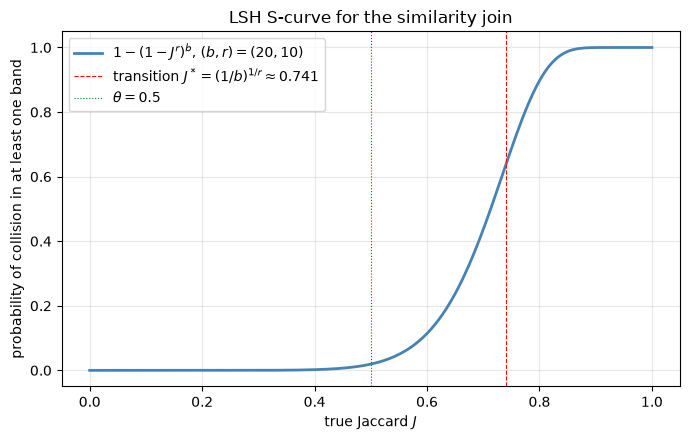

Mean planted J = 0.5436 (min 0.5385, max 0.6667)
Expected recall under the S-curve at observed planted Js: 0.0504
Empirical recall:                                          0.0500


In [12]:
candidates_in_planted = candidates & planted_pairs
n_tp_lsh = len(candidates_in_planted)

precision = n_tp_lsh / max(1, n_candidates)
recall = n_tp_lsh / max(1, len(planted_pairs))

print(f"Planted similar pairs: {len(planted_pairs)}")
print(f"LSH candidates:        {n_candidates}")
print(f"  of which planted:    {n_tp_lsh}")
print(f"  of which non-planted: {n_candidates - n_tp_lsh}")
print()
print(f"Precision = {n_tp_lsh}/{n_candidates} = {precision:.4f}")
print(f"Recall    = {n_tp_lsh}/{len(planted_pairs)} = {recall:.4f}")
print()

# Theoretical S-curve at (b, r) = (20, 10).
Js = np.linspace(0.0, 1.0, 200)
p_collide = 1.0 - (1.0 - Js ** R_ROWS) ** B_BANDS
transition = (1.0 / B_BANDS) ** (1.0 / R_ROWS)

fig, ax = plt.subplots(figsize=(7.0, 4.5))
ax.plot(Js, p_collide, lw=2.0, color="steelblue",
        label=f"$1 - (1 - J^r)^b$, $(b, r) = ({B_BANDS}, {R_ROWS})$")
ax.axvline(transition, color="red", linestyle="--", lw=0.8,
           label=f"transition $J^* = (1/b)^{{1/r}} \\approx {transition:.3f}$")
ax.axvline(0.5, color="green", linestyle=":", lw=0.8, label="$\\theta = 0.5$")
ax.set_xlabel("true Jaccard $J$")
ax.set_ylabel("probability of collision in at least one band")
ax.set_title("LSH S-curve for the similarity join")
ax.legend(loc="upper left")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Predict expected recall under the S-curve at the typical planted J.
planted_Js = np.array([jaccard(R1[i], R2[j]) for (i, j) in planted_list])
expected_recall = float(np.mean(1.0 - (1.0 - planted_Js ** R_ROWS) ** B_BANDS))
print(f"Mean planted J = {planted_Js.mean():.4f} (min {planted_Js.min():.4f}, max {planted_Js.max():.4f})")
print(f"Expected recall under the S-curve at observed planted Js: {expected_recall:.4f}")
print(f"Empirical recall:                                          {recall:.4f}")

### 5.8 The two stages read the same signature

The pipeline reports a pair when it is an LSH candidate **and** passes the threshold test. Both tests are functions of the same signature agreements, so they are dependent, and neither the product rule of `thm:join-rates` nor the gate rules of chapter 3 apply to the pipeline. What survives is the union bound, whatever the dependence: the pipeline's false-positive rate is at most that of either stage, and its false-negative rate is at most the sum of the two stages' false-negative rates.

For a single pair at true Jaccard $J$, the $k$ coordinate agreements are independent Bernoulli$(J)$ events, so all three probabilities can be computed exactly by a pass over the $b$ bands that tracks whether some band collided and how many coordinates agree in total. A Monte Carlo run on the same model checks the computation; the last lines apply the pipeline to the data above.

In [13]:
def stage_probabilities(J, b=B_BANDS, r=R_ROWS, theta=THETA):
    # Exact P(candidate), P(threshold), P(both) for one pair whose k = b r agreements are iid Bernoulli(J).
    k_sig = b * r
    band = np.array([math.comb(r, a) * J ** a * (1 - J) ** (r - a) for a in range(r + 1)])
    dist = np.zeros((2, k_sig + 1))               # [some band collided?, total agreements]
    dist[0, 0] = 1.0
    for _ in range(b):
        new = np.zeros_like(dist)
        for a in range(r + 1):
            moved = dist[:, : k_sig + 1 - a] * band[a]
            if a == r:                            # this band collides
                new[1, a:] += moved[0] + moved[1]
            else:
                new[:, a:] += moved
        dist = new
    need = math.ceil(theta * k_sig)
    p_cand = dist[1].sum()
    p_thr = dist[:, need:].sum()
    p_both = dist[1, need:].sum()
    return p_cand, p_thr, p_both


print(f"{'J':>5}  {'P(cand)':>9}  {'P(thr)':>9}  {'P(both)':>9}  {'product':>9}  {'both/product':>12}")
mc_rng = np.random.default_rng(1205)
for J in (0.45, 0.50, 0.55):
    p_cand, p_thr, p_both = stage_probabilities(J)
    assert math.isclose(p_cand, 1 - (1 - J ** R_ROWS) ** B_BANDS)
    print(f"{J:>5.2f}  {p_cand:>9.5f}  {p_thr:>9.5f}  {p_both:>9.5f}  {p_cand * p_thr:>9.5f}  "
          f"{p_both / (p_cand * p_thr):>12.2f}")
    # Monte Carlo check of the exact pass.
    T = 200_000
    agree = mc_rng.random((T, K_MINHASH)) < J
    cand = agree.reshape(T, B_BANDS, R_ROWS).all(axis=2).any(axis=1)
    thr = agree.mean(axis=1) >= THETA
    se = math.sqrt(p_both * (1 - p_both) / T)
    assert abs((cand & thr).mean() - p_both) < 4 * se
    if J < THETA:      # a negative pair: pipeline FPR is at most either stage's
        assert p_both <= min(p_cand, p_thr)
    else:              # a positive pair: pipeline FNR is at most the sum of the stages'
        assert 1 - p_both <= (1 - p_cand) + (1 - p_thr)

p_cand, p_thr, p_both = stage_probabilities(0.45)
assert p_both > 2 * p_cand * p_thr, "the product rule underestimates the pipeline FPR"
print(f"\nat J = 0.45 (a negative pair) the product rule predicts {p_cand * p_thr:.5f}; the pipeline "
      f"fires at {p_both:.5f}, bounded by min(stage FPRs) = {min(p_cand, p_thr):.5f}")

# The pipeline on the data: candidates that also pass the threshold test.
reported = {(i, j) for (i, j) in candidates if float(np.mean(sigs_R1[i] == sigs_R2[j])) >= THETA}
pipeline_recall = len(reported & planted_pairs) / len(planted_pairs)
print(f"pipeline on the data: {len(reported)} reported pairs, recall {pipeline_recall:.2f} "
      f"(LSH-stage recall {recall:.2f}, threshold-stage FNR on the sample {fnr:.2f})")
assert 1 - pipeline_recall <= (1 - recall) + fnr + 1e-12

    J    P(cand)     P(thr)    P(both)    product  both/product
 0.45    0.00679    0.08870    0.00189    0.00060          3.14


 0.50    0.01935    0.52817    0.01521    0.01022          1.49


 0.55    0.04946    0.93192    0.04872    0.04609          1.06



at J = 0.45 (a negative pair) the product rule predicts 0.00060; the pipeline fires at 0.00189, bounded by min(stage FPRs) = 0.00679
pipeline on the data: 5 reported pairs, recall 0.05 (LSH-stage recall 0.05, threshold-stage FNR on the sample 0.07)


### 5.9 The chapter's worked example

Take $|R_1| = |R_2| = 1000$ ($10^6$ candidate pairs), $\theta = 0.5$, and $k = 200$ as $b = 20$ bands of $r = 10$. The threshold test is sharp: a pair at $J = 0.3$ is emitted with probability at most $e^{-2 \cdot 200 \cdot 0.2^2} = e^{-16} \approx 1.1 \times 10^{-7}$. The banding dominates: its transition sits at $J^* = (1/20)^{1/10} \approx 0.74$, above the threshold, and the survival probability $1 - (1 - J^{10})^{20}$ is about $0.436$ at $J = 0.7$, $0.0194$ at $J = 0.5$, and $1.18 \times 10^{-4}$ at $J = 0.3$. If $0.1\%$ of pairs have $J \ge 0.5$, $1\%$ lie in $[0.3, 0.5)$, and the rest below $0.3$, with $J = 0.7, 0.5, 0.3$ as representatives (upper estimates for the last two bands), the candidate set is about $747$ pairs, verified with about $1.5 \times 10^5$ signature comparisons against $2 \times 10^8$ for the naive scan. The cost is recall: fewer than half of the strongly similar pairs and about $2\%$ of threshold pairs survive.

In [14]:
def survival(J, b=B_BANDS, r=R_ROWS):
    return 1 - (1 - J ** r) ** b


hoeffding = math.exp(-2 * K_MINHASH * (THETA - 0.3) ** 2)
j_star = (1 / B_BANDS) ** (1 / R_ROWS)
counts = {0.7: 1000, 0.5: 10_000, 0.3: 989_000}
n_cand = sum(n_pairs_band * survival(J) for J, n_pairs_band in counts.items())
print(f"Hoeffding bound at J = 0.3: e^-16 = {hoeffding:.2e};  transition J* = {j_star:.3f}")
print("survival: " + ", ".join(f"J = {J}: {survival(J):.4g}" for J in counts))
print(f"expected candidates: {n_cand:.0f};  signature comparisons {n_cand * K_MINHASH:.2e} "
      f"against {1e6 * K_MINHASH:.0e} for the naive scan")
assert round(survival(0.7), 3) == 0.436 and round(survival(0.5), 4) == 0.0194
assert math.isclose(survival(0.3), 1.18e-4, rel_tol=0.01) and round(n_cand) == 747
assert round(j_star, 2) == 0.74 and math.isclose(hoeffding, 1.1e-7, rel_tol=0.05)

Hoeffding bound at J = 0.3: e^-16 = 1.13e-07;  transition J* = 0.741
survival: J = 0.7: 0.4362, J = 0.5: 0.01935, J = 0.3: 0.0001181
expected candidates: 747;  signature comparisons 1.49e+05 against 2e+08 for the naive scan


## 6. Discussion: A Tuple's Rate Versus a Query's Error

One distinction carries the chapter: a tuple's rate is a property of one probe, while a query's error depends on which stored outcomes its probes share.

- **Operators.** Selection with an exact predicate keeps each truth class's rates. Projection amplifies false positives with rates indexed by the fiber profile $(k, j)$; under shared sources its outputs are correlated by the source-overlap covariance law (`thm:projection-shared-sources`). A join is correct per tuple, with three pointwise false-positive regimes, and it correlates outputs that share an operand tuple (§§1 to 2). Composing operators requires the lineage over sources, not a chain of per-operator rate updates: a join output is not a two-rate tuple, join-then-project fibers share sources, and repeated sources are not fresh trials.
- **Queries.** The truth-uniform contract $1 - (1 - \fprate)^{s_0}$ under independent one-sided sources is the right target, not a convenient test profile: on the 12-cycle, sources sized at the tuple target $0.05$ pass an all-false check yet allow a query false-positive rate near $0.33$, and calibrated sizing restores about $0.05$ (§§3 to 4). The stored-filter experiment demonstrates compatibility with the ideal model, not a certificate that a concrete keyed hash attains it.
- **Sketch-based joins.** The threshold relation $[\hat J \ge \theta]$ and the LSH candidate relation are approximate relations on $T \times U$ with pointwise rates, but they read the same signature, so they are dependent and compose only through sound bounds such as the union bound (§5).

Chapter 13 organizes approximate sets, functions, relations, and sketches as $\Bernoulli{T}$ constructors; an approximate relation is $\Bernoulli{\BoolType}$ on a product universe, and the type view supplies its marginal rates. The lesson of this chapter travels with it: marginals compose cleanly, but joint behavior is fixed by shared sources, which a type signature alone does not record. Approximate relations can also model the *functionality* of a private search index, but equal error rates say nothing about confidentiality (`rem:ch12-encrypted-scope`); chapters 17 and 18 take that up separately.

**What this notebook verified:**

| Section | Claim | Verified |
|---------|-------|----------|
| §1 sources | repeated source fires at $\fprate$, not $\fprate^8$; shared-pair join outputs have covariance $a(1-a)b_1b_2 = 0.0729$ | yes (asserted, exact) |
| §2 operators | projection rates $0.90975$ and $0.9905$ at $(3,1)$, $(3,2)$; join regimes $0.001$ and $0.02$ | yes (asserted, exact) |
| §3 contracts | $\mathcal{E}_0 = 1 - (1-\fprate)^{s_0}$ on cycles of 3 to 10; 12-cycle $s_0 = 8$, worst FPR $0.337$ at $\{0,3,6,9\}$; two-sided caveat; calibration formula | yes (asserted, exact) |
| §4 calibration | per-tuple sizing: boundary FPR near $0.33$; per-query sizing: about $0.05$; bytes $2{,}250$ and $3{,}752$ | yes (asserted, 64 builds per sizing) |
| §5 MinHash and LSH | estimator within $\pm 0.05$ of $J$; candidate set sub-quadratic; recall matches the S-curve | yes (reported) |
| §5.8 dependence | candidate and threshold tests are dependent; product rule fails; union bounds hold | yes (asserted) |
| §5.9 worked example | survival $0.436$, $0.0194$, $1.18 \times 10^{-4}$; about $747$ candidates | yes (asserted) |